# EV Charging Demand Classification

## Project objective
The goal of classification is to predict whether an EV charging session belongs to:

- **Normal Demand = 0**
- **High Demand = 1**

## 1. Load and inspect the dataset

- `pd.read_csv(...)` loads the prepared EV charging dataset into a pandas DataFrame called `df`.
- `df.columns` shows all available columns.
- `df.shape` shows the number of rows and columns.

### Output
The dataset contains **72,241 rows and 17 columns**.

In [1]:
import pandas as pd

# 1. Load the dataset
df = pd.read_csv('data/ev_charging_featured.csv')

# Convert the timestamp into datetime format
df["start_full"] = pd.to_datetime(
    df["start_full"],
    errors="coerce"
)

# Sort sessions from oldest to newest
df = (
    df.sort_values("start_full")
    .reset_index(drop=True)
)

# 2. Display column names
print("---Column names---")
print(df.columns)

# 3. Display dataset size
print("\n---Dataset size---")
print(df.shape)

---Column names---
Index(['chargercompany', 'location', 'chargertype', 'duration', 'demand',
       'start_full', 'start_hour', 'start_day', 'start_minute', 'week_of_year',
       'day_name', 'month_name', 'day_type', 'time_of_day',
       'user_previous_sessions', 'charger_previous_sessions',
       'location_previous_sessions'],
      dtype='object')

---Dataset size---
(72241, 17)


## 2. Create the classification target

The original `demand` column is numeric. A classification model needs categories, so this code converts demand into two classes.

1. The median demand is calculated.
2. The median is **14.25**.
3. If `demand >= 14.25`, the row is labeled **High Demand**.
4. If `demand < 14.25`, the row is labeled **Normal Demand**.
5. The text labels are mapped to numbers:
   - **Normal Demand → 0**
   - **High Demand → 1**

The median creates a simple split around the middle of the demand values. In this dataset it also produces almost equal class sizes.

In [2]:
import numpy as np

# Calculate the median demand
median_demand = df['demand'].median()

print("Median Demand:", median_demand)

# Create the demand category target
df['demand_category'] = np.where(
    df['demand'] >= median_demand,
    'High Demand',
    'Normal Demand'
)

# Convert text labels into numeric labels for classification
df['target'] = df['demand_category'].map({
    'Normal Demand': 0,
    'High Demand': 1
})

# Check the number of rows in each class
print(df['demand_category'].value_counts())

Median Demand: 14.25
demand_category
High Demand      36143
Normal Demand    36098
Name: count, dtype: int64


## 3. Check class balance

The classes are nearly equally distributed (50.03% High Demand and 49.97% Normal Demand).

- **High Demand: 50.03%**
- **Normal Demand: 49.97%**

Since the target classes were already balanced, Random Oversampling, SMOTE, and ADASYN were not applied.

In [3]:
df['demand_category'].value_counts(normalize=True) * 100

demand_category
High Demand      50.031146
Normal Demand    49.968854
Name: proportion, dtype: float64

## 4. Select features and create a chronological train-test split

### Feature groups

**Numeric features** contain numbers such as:
- duration
- start day/hour/minute
- week of year
- previous session counts

**Categorical features** contain labels such as:
- location
- time of day
- charger type
- charger company
- day_name
- month_name
- day_type

`x` contains the model input features and `y` contains the target.

The first 80% of rows are used for training and the last 20% are used for testing.

There is **no shuffling**. This is useful when the row order represents time because the model learns from earlier observations and is tested on later observations.

### Split balance
The training and testing sets both remain close to 50-50 between the two classes.

In [4]:
month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

numeric_features = [
    "duration",
    "start_day",
    "start_hour",
    "start_minute",
    "week_of_year",
    "user_previous_sessions",
    "charger_previous_sessions",
    "location_previous_sessions"
]

standard_categorical_features = [
    "chargercompany",
    "location",
    "chargertype",
    "day_type",
    "time_of_day"
]

calendar_categorical_features = [
    "month_name",
    "day_name"
]

expected_months = set(month_order)
expected_days = set(day_order)

assert set(df["month_name"].unique()).issubset(
    expected_months
), "Unexpected month name found."

assert set(df["day_name"].unique()).issubset(
    expected_days
), "Unexpected day name found."

# 3. Separate model inputs (x) and classification target (y)
x = df[numeric_features + standard_categorical_features + calendar_categorical_features]
y = df['target']

# 2. Chronological 80/20 train-test split (no shuffling)
split_idx = int(len(df) * 0.80)

x_train = x.iloc[:split_idx]
x_test = x.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

# 3. Check class distribution in the training and testing sets
print("\n--- Training Set Class Balance ---")
print(y_train.value_counts(normalize=True) * 100)

print("\n--- Testing Set Class Balance ---")
print(y_test.value_counts(normalize=True) * 100)



--- Training Set Class Balance ---
target
1    50.299349
0    49.700651
Name: proportion, dtype: float64

--- Testing Set Class Balance ---
target
0    51.041595
1    48.958405
Name: proportion, dtype: float64


## 5. Preprocessing

Different feature types need different preparation before they are passed to the models.

### Numeric features — `StandardScaler`
`StandardScaler()` places numeric features on a comparable scale.

### Categorical features — `OneHotEncoder`
`OneHotEncoder()` converts text categories into numeric indicator columns.

- `drop='first'` removes one reference category from each categorical feature.
- `handle_unknown='ignore'` prevents an error if a category appears in test data that was not seen during training.

### ColumnTransformer
ColumnTransformer applies three preprocessing groups. Numerical features are standardized, regular categorical features are One-Hot Encoded using categories learned from the training set, and calendar features are One-Hot Encoded using predefined month and weekday category lists.

### Pipeline
Each model later combines this preprocessor with the classifier. This keeps preprocessing and modeling together and helps ensure the same transformations are applied consistently.

In [5]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            standard_categorical_features
        ),
        (
            "calendar",
            OneHotEncoder(
                categories=[
                    month_order,
                    day_order
                ],
                drop="first",
                handle_unknown="ignore"
            ),
            calendar_categorical_features
        )
    ]
)


## 6. Evaluation metrics used for every model

### Inputs
- `y_test` = actual class labels
- `y_pred` = predicted class labels
- `y_proba` = predicted probability/score for **High Demand (class 1)**

### Accuracy
**Question:** Out of all test rows, how many were classified correctly?

Higher is better, but accuracy should not be considered alone.

### Precision
**Question:** Out of all rows predicted as **High Demand**, how many were actually High Demand?

High precision means fewer **false high-demand alerts**.

### Recall
**Question:** Out of all actual **High Demand** rows, how many did the model successfully find?

High recall means fewer real high-demand cases are missed.

### F1 Score
F1 combines **Precision and Recall** into one balanced score.

It is useful when both false positives and false negatives matter.

### ROC-AUC
ROC-AUC measures how well the model separates High Demand from Normal Demand across different classification thresholds.

- Around **0.5** = weak/random separation
- Closer to **1.0** = stronger separation

In [6]:
def evaluate_model(model_name, y_test, y_pred, y_proba):
    print(f"\n=== {model_name} ===")

    print(
        "Accuracy :",
        round(accuracy_score(y_test, y_pred), 4)
    )

    print(
        "Precision:",
        round(precision_score(y_test, y_pred), 4)
    )

    print(
        "Recall   :",
        round(recall_score(y_test, y_pred), 4)
    )

    print(
        "F1 Score :",
        round(f1_score(y_test, y_pred), 4)
    )

    print(
        "ROC-AUC  :",
        round(roc_auc_score(y_test, y_proba), 4)
    )


## 7. Logistic Regression

Logistic Regression is a simple binary classification model. It estimates the probability that a row belongs to class 1, which is **High Demand** in this dataset.

- The preprocessing step and Logistic Regression are combined in one pipeline.
- `.fit()` learns from the training data.
- `.predict()` returns the final class prediction: 0 or 1.
- `.predict_proba()[:, 1]` returns the probability of class 1 (High Demand).
- Those predictions are passed to the common evaluation function.

### Results
- **Accuracy:** 0.8276
- **Precision:** 0.8265
- **Recall:** 0.8200
- **F1:** 0.8232
- **ROC-AUC:** 0.8881

### Interpretation
Logistic Regression provides a strong baseline model, achieving 82.76% accuracy despite its relatively simple linear decision boundary.
Of the rows predicted as High Demand, about **82.65%** were actually High Demand. The model identified about **82.00%** of the actual High Demand rows.

ROC-AUC of **0.8881** shows that the model separates the two classes reasonably well.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# 1. Create a pipeline that combines preprocessing and Logistic Regression
# max_iter=1000 gives the algorithm enough iterations to converge
log_reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# 2. Train the model using the training data
log_reg_pipeline.fit(x_train, y_train)

# 3. Generate class predictions and class-1 probabilities for the test data
y_pred_lr = log_reg_pipeline.predict(x_test)

# [:, 1] selects the probability of class 1, which represents High Demand
y_proba_lr = log_reg_pipeline.predict_proba(x_test)[:, 1]

# 4. Evaluate the model
lr_results = evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_lr,
    y_proba_lr
)



=== Logistic Regression ===
Accuracy : 0.8276
Precision: 0.8265
Recall   : 0.82
F1 Score : 0.8232
ROC-AUC  : 0.8881


## 8. Decision Tree

A Decision Tree makes predictions through a sequence of rules, such as asking whether a feature is above or below a certain split value.

`max_depth=10` limits how deep the tree can grow and helps control excessive complexity.

### Results
- **Accuracy:** 0.8612
- **Precision:** 0.8379
- **Recall:** 0.8885
- **F1:** 0.8624
- **ROC-AUC:** 0.8958

### Interpretation
The Decision Tree correctly classifies about **86.12%** of the test data and finds about **88.85%** of actual High Demand cases.

It improves on Logistic Regression in Accuracy, Recall, and F1. However, the later train-vs-test check shows a larger gap than the boosting models, which is a sign that the tree is learning the training data more strongly.

In [8]:
from sklearn.tree import DecisionTreeClassifier

# max_depth=10 limits tree depth and helps control overfitting
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=10, random_state=42))
])

# 2. Train the model
dt_pipeline.fit(x_train, y_train)

# 3. Generate predictions and probabilities
y_pred_dt = dt_pipeline.predict(x_test)
y_proba_dt = dt_pipeline.predict_proba(x_test)[:, 1]

# 4. Evaluate the model
dt_results = evaluate_model(
    "Decision Tree",
    y_test,
    y_pred_dt,
    y_proba_dt
)



=== Decision Tree ===
Accuracy : 0.8612
Precision: 0.8379
Recall   : 0.8885
F1 Score : 0.8624
ROC-AUC  : 0.8958


## 9. Random Forest

Random Forest builds many Decision Trees and combines their predictions.

Instead of depending on one tree, multiple trees vote together. This usually makes the result more stable than a single Decision Tree.

### parameters
- `n_estimators=100` → builds 100 trees
- `max_depth=10` → limits tree depth
- `n_jobs=-1` → uses available CPU cores to speed up training

### Results
- **Accuracy:** 0.8750
- **Precision:** 0.8286
- **Recall:** 0.9389
- **F1:** 0.8803
- **ROC-AUC:** 0.9339

### Interpretation
Random Forest has the **highest Recall (0.9389)** among all five models.

That means it detects about **93.89% of the actual High Demand cases**. This is especially useful if missing a real high-demand case is costly.

Its Precision is lower than XGBoost and LightGBM, so its stronger recall comes with more false-positive High Demand predictions.


In [9]:
from sklearn.ensemble import RandomForestClassifier

# 1. Create the pipeline
# n_estimators=100 builds 100 trees, and random_state=42 makes results reproducible
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    (
        'classifier',
        RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            random_state=42,
            n_jobs=-1
        )
    )
])

# 2. Train the model
rf_pipeline.fit(x_train, y_train)

# 3. Generate predictions and probabilities
y_pred_rf = rf_pipeline.predict(x_test)
y_proba_rf = rf_pipeline.predict_proba(x_test)[:, 1]

# 4. Evaluate the model
rf_results = evaluate_model(
    "Random Forest",
    y_test,
    y_pred_rf,
    y_proba_rf
)



=== Random Forest ===
Accuracy : 0.8765
Precision: 0.8314
Recall   : 0.9381
F1 Score : 0.8815
ROC-AUC  : 0.9345


## 10. XGBoost

XGBoost is a boosting algorithm. It builds trees sequentially, where each new tree focuses on correcting errors made by the previous trees.

### parameters
- `n_estimators=100` → number of boosting trees
- `learning_rate=0.1` → controls how strongly each new tree contributes
- `max_depth=5` → limits the complexity of each tree
- `eval_metric='logloss'` → uses classification log loss during training

### Results
- **Accuracy:** 0.8860
- **Precision:** 0.8547
- **Recall:** 0.9244
- **F1:** 0.8881
- **ROC-AUC:** 0.9505

### Interpretation
XGBoost achieves **Accuracy of 0.8860** and **Precision of 0.8547**. It also has the **highest ROC-AUC (0.9505)** among the five models.

It also has very strong Recall. This means it performs well both in correctly classifying the test data and in separating High Demand from Normal Demand.

In [10]:
import xgboost as xgb

# 1. Create the pipeline
# eval_metric='logloss' specifies the classification loss used during training
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    (
        'classifier',
        xgb.XGBClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=5,
            random_state=42,
            eval_metric='logloss'
        )
    )
])

# 2. Train the model
xgb_pipeline.fit(x_train, y_train)

# 3. Generate predictions and probabilities
y_pred_xgb = xgb_pipeline.predict(x_test)
y_proba_xgb = xgb_pipeline.predict_proba(x_test)[:, 1]

# 4. Evaluate the model
xgb_results = evaluate_model(
    "XGBoost",
    y_test,
    y_pred_xgb,
    y_proba_xgb
)



=== XGBoost ===
Accuracy : 0.886
Precision: 0.8547
Recall   : 0.9244
F1 Score : 0.8881
ROC-AUC  : 0.9505


## 11. LightGBM

LightGBM is another gradient-boosting tree algorithm. Like XGBoost, trees are built to improve the errors of the earlier trees, but LightGBM uses an efficient tree-growing approach designed for fast training.

### parameters
- `n_estimators=100`
- `learning_rate=0.1`
- `max_depth=5`
- `verbose=-1` hides unnecessary training messages

### Results
- **Accuracy:** 0.8880
- **Precision:** 0.8561
- **Recall:** 0.9269
- **F1:** 0.8901
- **ROC-AUC:** 0.9496

### Interpretation
LightGBM has the **highest Accuracy (0.8880)**, **Precision (0.8561)**, and **F1 Score (0.8901)**. LightGBM provides the best balance between Precision and Recall, making it the most suitable model for predicting High Demand sessions.

Its Accuracy is almost identical to XGBoost: **0.8880 vs 0.8860**. It also has slightly higher Recall than XGBoost.

### Important comparison
There is no large performance difference between XGBoost and LightGBM here.

-  **XGBoost** if the main focus is the highest ROC-AUC.
-  **LightGBM** if the main focus is the best Accuracy, Precision, and F1 balance, with slightly higher Recall.


In [11]:
import lightgbm as lgb

# 1. Create the pipeline
# verbose=-1 suppresses unnecessary LightGBM training messages
lgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    (
        'classifier',
        lgb.LGBMClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=5,
            random_state=42,
            verbose=-1
        )
    )
])

# 2. Train the model
lgb_pipeline.fit(x_train, y_train)

# 3. Generate predictions and probabilities
y_pred_lgb = lgb_pipeline.predict(x_test)
y_proba_lgb = lgb_pipeline.predict_proba(x_test)[:, 1]

# 4. Evaluate the model
lgb_results = evaluate_model(
    "LightGBM",
    y_test,
    y_pred_lgb,
    y_proba_lgb
)



=== LightGBM ===
Accuracy : 0.888
Precision: 0.8561
Recall   : 0.9269
F1 Score : 0.8901
ROC-AUC  : 0.9496


# 13. Final model comparison

| Model | Accuracy | Precision | Recall | F1 Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.8276 | 0.8265 | 0.8200 | 0.8232 | 0.8881 |
| Decision Tree | 0.8612 | 0.8379 | 0.8885 | 0.8624 | 0.8958 |
| Random Forest | 0.8750 | 0.8286 | 0.9389 | 0.8803 | 0.9339 |
| XGBoost | 0.8860 | 0.8547 | 0.9244 | 0.8881 | 0.9505 |
| LightGBM | 0.8880 | 0.8561 | 0.9269 | 0.8901 | 0.9496 |


- **Highest Accuracy:** LightGBM — 0.8880
- **Highest Precision:** LightGBM — 0.8561
- **Highest Recall:** Random Forest — 0.9389
- **Highest F1:** LightGBM — 0.8901
- **Highest ROC-AUC:** XGBoost — 0.9505

### Overall interpretation
**XGBoost and LightGBM are the strongest overall models in this notebook.** Their results are extremely close.

Based on overall performance across Accuracy, Precision, Recall, F1 Score, and ROC-AUC, LightGBM was selected as the final classification model because it has the highest Accuracy, Precision, and F1 Score in the saved test results.

## 15. Train vs Test Accuracy — overfitting check

This section compares each model's accuracy on:
- the data used for training
- unseen test data

A larger positive gap means the model performs noticeably better on training data than on test data. That can be a sign of overfitting.

### Results

| Model | Train Accuracy | Test Accuracy | Train − Test Gap |
|---|---:|---:|---:|
| Logistic Regression | 0.8407 | 0.8276 | 1.31% |
| Decision Tree | 0.9196 | 0.8612 | 5.83% |
| Random Forest | 0.9079 | 0.8750 | 3.29% |
| XGBoost | 0.9109 | 0.8860 | 2.49% |
| LightGBM | 0.9116 | 0.8880 | 2.36% |


- **Logistic Regression:** training accuracy is slightly higher than test accuracy, with a gap of 1.31%.
- **Decision Tree:** noticeable gap of 5.83%.
- **Random Forest:** moderate gap of 3.29%.
- **XGBoost:** small gap of 2.49% with strong test accuracy.
- **LightGBM:** small gap of 2.36% and the highest test accuracy among the five models.

In [12]:
# Group all trained models into a dictionary
trained_models = {
    "Logistic Regression": log_reg_pipeline,
    "Decision Tree": dt_pipeline,
    "Random Forest": rf_pipeline,
    "XGBoost": xgb_pipeline,
    "LightGBM": lgb_pipeline,
}

print("=== Train vs Test Accuracy Check (Overfitting Analysis) ===")

for name, pipeline in trained_models.items():
    # 1. Predict on both training and testing sets
    y_pred_train = pipeline.predict(x_train)
    y_pred_test = pipeline.predict(x_test)

    # 2. Calculate accuracies
    train_acc = accuracy_score(y_train, y_pred_train)
    test_acc = accuracy_score(y_test, y_pred_test)

    # 3. Calculate the train-test accuracy difference
    diff = (train_acc - test_acc) * 100

    # 4. Print the results
    print(f"\n{name}:")
    print(f"  Train Accuracy : {round(train_acc, 4)}")
    print(f"  Test Accuracy  : {round(test_acc, 4)}")
    print(f"  Difference     : {round(diff, 2)}%")


=== Train vs Test Accuracy Check (Overfitting Analysis) ===

Logistic Regression:
  Train Accuracy : 0.8407
  Test Accuracy  : 0.8276
  Difference     : 1.31%

Decision Tree:
  Train Accuracy : 0.9196
  Test Accuracy  : 0.8612
  Difference     : 5.83%

Random Forest:
  Train Accuracy : 0.9075
  Test Accuracy  : 0.8765
  Difference     : 3.1%

XGBoost:
  Train Accuracy : 0.9109
  Test Accuracy  : 0.886
  Difference     : 2.49%

LightGBM:
  Train Accuracy : 0.9116
  Test Accuracy  : 0.888
  Difference     : 2.36%


## 16. LightGBM feature importance

This section uses the trained LightGBM model to identify which input features contributed most strongly to its decisions.

1. Extracts the fitted LightGBM classifier from the pipeline.
2. Retrieves the feature names after preprocessing.
3. Gets LightGBM's feature-importance scores.
4. Sorts the scores from highest to lowest.
5. Prints and plots the top 20 features.

### Graph interpretation
The horizontal bar chart shows **relative feature importance**.

The strongest features are:
1. **duration**
2. **user_previous_sessions**
3. **location_previous_sessions**
4. **start_hour**
5. **charger_previous_sessions**
6. **week_of_year**

`duration` has the largest importance score, so the LightGBM model relies on it heavily when separating High Demand and Normal Demand.

=== Top 20 Features Driving Predictions ===
                        Feature  Importance
0                      duration         715
1        user_previous_sessions         376
2                    start_hour         274
3    location_previous_sessions         270
4     charger_previous_sessions         250
5                  week_of_year         163
6                  start_minute          86
7              chargercompany_1          84
8               location_market          75
9                 chargertype_1          65
10                    start_day          60
11         location_public area          58
12           location_apartment          43
13              location_resort          43
14             location_company          40
15  location_public institution          37
16               location_hotel          35
17              day_name_Sunday          22
18             location_camping          19
19          location_restaurant          16


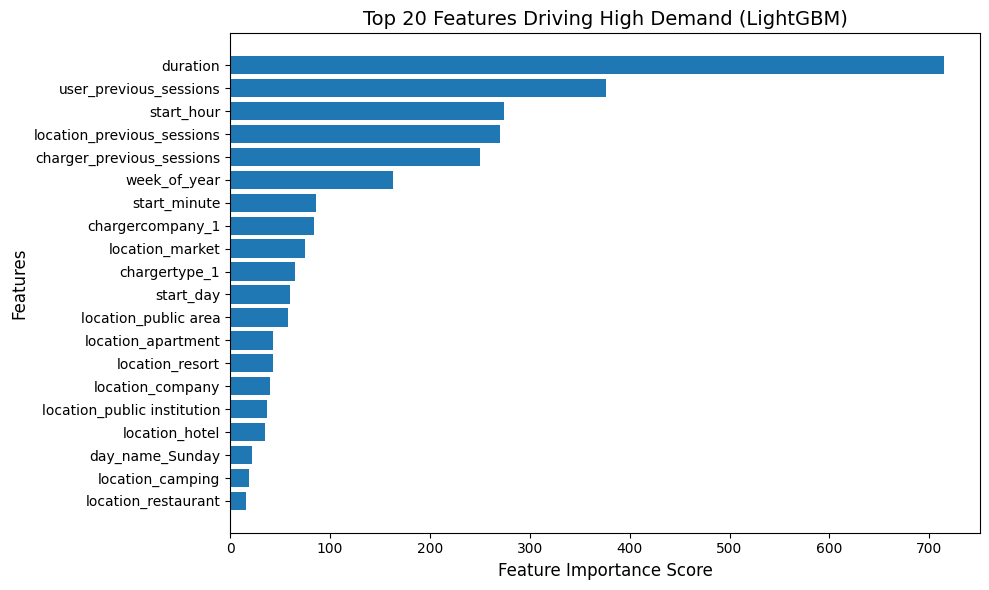

In [13]:
import matplotlib.pyplot as plt
import os

# 1. Extract the trained model and preprocessor from the LightGBM pipeline
best_model = lgb_pipeline.named_steps['classifier']
preprocessor_step = lgb_pipeline.named_steps['preprocessor']

# 2. Get ALL transformed feature names, including numerical, categorical and calendar features
all_feature_names = preprocessor_step.get_feature_names_out()

# 3. Get feature importances in the same column order
importances = best_model.feature_importances_

clean_feature_names = [
    feature_name.split("__", 1)[-1]
    for feature_name in all_feature_names
]

# 4. Create a DataFrame for sorting and viewing
#importance_df = pd.DataFrame({
#    'Feature': all_feature_names,
#    'Importance': importances
#})

importance_df = pd.DataFrame({
    "Feature": clean_feature_names,
    "Importance":
        best_model.feature_importances_
})

# Sort from highest to lowest importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

# Print the top 20 factors
print("=== Top 20 Features Driving Predictions ===")
print(importance_df.head(20))

# 5. Plot feature importances
plt.figure(figsize=(10, 6))

# Reverse the top 20 so the most important feature appears at the top
plt.barh(
    importance_df['Feature'].head(20)[::-1],
    importance_df['Importance'].head(20)[::-1],
    color='#1f77b4'
)

plt.title('Top 20 Features Driving High Demand (LightGBM)', fontsize=14)
plt.xlabel('Feature Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()

# Ensure the images folder exists before saving
os.makedirs("images", exist_ok=True)
plt.savefig(
    "images/classification_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## Confusion matrix

In each confusion matrix, rows represent actual classes and columns represent predicted classes. The top-left and bottom-right cells contain correct predictions. The top-right cell represents Normal Demand sessions incorrectly classified as High Demand. The bottom-left cell represents High Demand sessions incorrectly classified as Normal Demand.

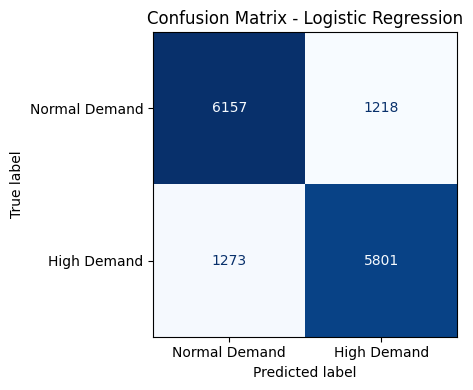

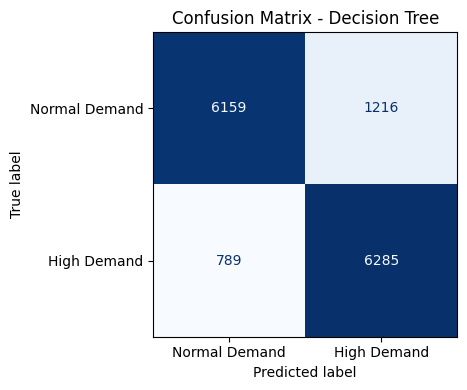

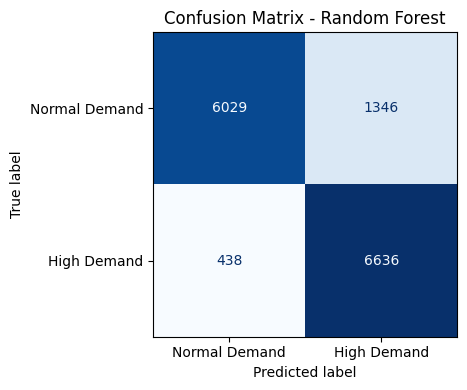

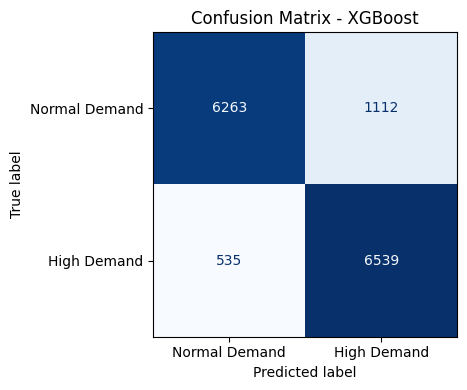

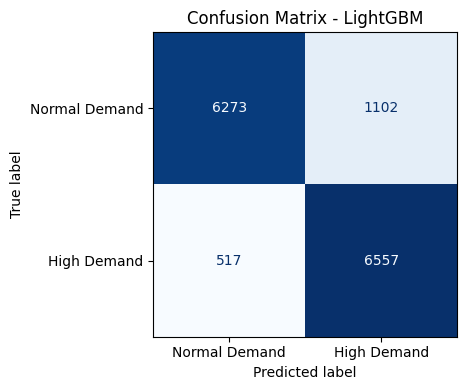

In [14]:
# Confusion Matrix for all Classification Models

import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Create images folder
os.makedirs("images", exist_ok=True)

# Store model predictions
model_predictions = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb,
    "LightGBM": y_pred_lgb
}

# Create confusion matrix for every model
for model_name, y_pred in model_predictions.items():

    # Calculate confusion matrix
    cm = confusion_matrix(y_test,y_pred)

    # Create figure
    fig, ax = plt.subplots(figsize=(5, 4))

    # Display confusion matrix
    display = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Normal Demand","High Demand"])

    display.plot(ax=ax,cmap="Blues",values_format="d",colorbar=False)

    ax.set_title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    
    # Create safe file name
    file_name = (model_name.lower().replace(" ", "_"))

    # Save image
    plt.savefig(f"images/confusion_matrix_{file_name}.png",dpi=300,bbox_inches="tight")

    plt.show()

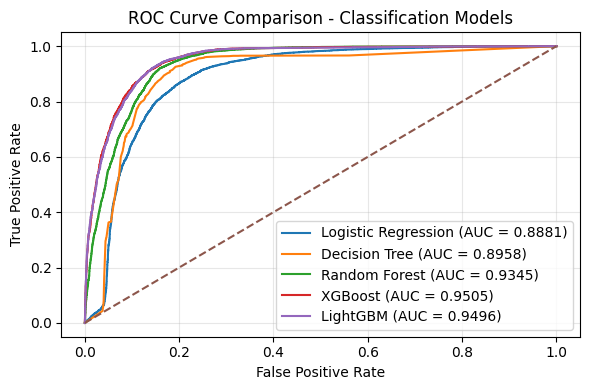

In [15]:
# ROC Curve Comparison

from sklearn.metrics import roc_curve, auc

# Store predicted probabilities
model_probabilities = {
    "Logistic Regression": y_proba_lr,
    "Decision Tree": y_proba_dt,
    "Random Forest": y_proba_rf,
    "XGBoost": y_proba_xgb,
    "LightGBM": y_proba_lgb
}

plt.figure(figsize=(6, 4))

for model_name, y_proba in model_probabilities.items():

    # Calculate False Positive Rate
    # and True Positive Rate
    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_proba
    )

    # Calculate AUC
    roc_auc = auc(
        fpr,
        tpr
    )

    # Plot ROC curve
    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {roc_auc:.4f})"
    )


# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)


plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve Comparison - Classification Models"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()


# Save graph
plt.savefig(
    "images/classification_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
import pickle

with open("models/lightgbm_classification.pkl", "wb") as file:
    pickle.dump(lgb_pipeline, file)

In [17]:
with open("models/lightgbm_classification.pkl", "rb") as file:
    classification_model = pickle.load(file)

In [18]:
print(type(classification_model))

<class 'sklearn.pipeline.Pipeline'>
